
# 05 — Evaluasi Sistem Rekomendasi SmartLibrary AI

## Tujuan

Mengevaluasi kualitas rekomendasi buku berbasis
TF-IDF dan Cosine Similarity.

## Aspek Evaluasi

1. Precision@5
2. Precision@10
3. Konsistensi rekomendasi bilingual
4. Analisis buku yang relevan dan tidak relevan

## Metodologi

Evaluasi dilakukan menggunakan sejumlah permintaan
buku dengan topik berbeda.

Sistem menghasilkan Top 10 rekomendasi untuk setiap
permintaan. Setiap buku kemudian dinilai secara manual
berdasarkan kesesuaian judul, kategori, dan sinopsis
dengan kebutuhan pengguna.

Penilaian relevansi:
- 1 = Relevan
- 0 = Tidak relevan

Hasil penilaian digunakan untuk menghitung Precision@5
dan Precision@10.

Catatan: Skor Cosine Similarity bukan label relevansi.


## Tujuan dan keluaran

- Susun pertanyaan evaluasi dan penilaian relevansi yang terdokumentasi.
- Bangun baseline pencarian kata kunci untuk perbandingan.
- Hitung Precision@5 dengan label relevansi yang disepakati.
- Analisis kueri berhasil dan gagal, termasuk kueri berbahasa Indonesia.
- Simpan tabel evaluasi dan grafik ringkas untuk presentasi PKA.

## Tahapan yang akan dikerjakan

1. Susun pertanyaan evaluasi dan penilaian relevansi yang terdokumentasi.
2. Bangun baseline pencarian kata kunci untuk perbandingan.
3. Hitung Precision@5 dengan label relevansi yang disepakati.
4. Analisis kueri berhasil dan gagal, termasuk kueri berbahasa Indonesia.
5. Simpan tabel evaluasi dan grafik ringkas untuk presentasi PKA.

## Catatan

Tahap ini akan diisi dengan kode per cell dan penjelasan yang lengkap ketika kita memulai notebook terkait. Jangan menyimpan hasil olahan ke `dataset/raw/`.

In [1]:

# =====================================================
# CELL 2 - MEMBACA DATASET DAN MODEL
# =====================================================

from pathlib import Path

import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity

# Menemukan folder utama project
current_dir = Path.cwd().resolve()

ROOT = next(
    (
        folder for folder in
        [current_dir, *current_dir.parents]
        if (
            folder / "models" /
            "smartlibrary_tfidf.joblib"
        ).is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Folder project atau model tidak ditemukan!"
    )

# Lokasi file
DATA_PATH = (
    ROOT / "dataset" / "processed" /
    "books_clean.csv"
)

MODEL_PATH = (
    ROOT / "models" /
    "smartlibrary_tfidf.joblib"
)

# Membaca dataset
df_books = pd.read_csv(
    DATA_PATH,
    dtype={
        "isbn13": "string",
        "isbn10": "string"
    }
).reset_index(drop=True)

# Membaca model
model_bundle = joblib.load(MODEL_PATH)

tfidf_vectorizer = model_bundle["vectorizer"]
tfidf_matrix = model_bundle["tfidf_matrix"]

print("=" * 55)
print("EVALUASI SMARTLIBRARY AI")
print("=" * 55)

print("Jumlah buku :", len(df_books))
print("Fitur TF-IDF:", tfidf_matrix.shape[1])
print("Model       :", MODEL_PATH.name)

print("\n[OK] Dataset dan model berhasil dimuat.")


EVALUASI SMARTLIBRARY AI
Jumlah buku : 5094
Fitur TF-IDF: 40000
Model       : smartlibrary_tfidf.joblib

[OK] Dataset dan model berhasil dimuat.


In [2]:

# =====================================================
# CELL 3 - VALIDASI MODEL UNTUK EVALUASI
# =====================================================

# Memastikan jumlah baris sesuai
assert tfidf_matrix.shape[0] == len(df_books), (
    "Jumlah buku dan baris TF-IDF berbeda!"
)

# Memastikan urutan ISBN sesuai
saved_isbns = model_bundle["book_isbns"]

current_isbns = (
    df_books["isbn13"].astype(str).tolist()
)

assert saved_isbns == current_isbns, (
    "Urutan buku berbeda dengan model!"
)

# Memastikan tidak ada ISBN duplikat
assert df_books["isbn13"].is_unique

# Memastikan model memiliki fitur
assert tfidf_matrix.shape[1] > 0

print("=" * 55)
print("VALIDASI MODEL EVALUASI")
print("=" * 55)

print("[OK] Jumlah buku sesuai.")
print("[OK] Urutan ISBN sesuai.")
print("[OK] ISBN unik.")
print("[OK] Matriks TF-IDF tersedia.")

print("\n[OK] Model siap untuk evaluasi.")


VALIDASI MODEL EVALUASI
[OK] Jumlah buku sesuai.
[OK] Urutan ISBN sesuai.
[OK] ISBN unik.
[OK] Matriks TF-IDF tersedia.

[OK] Model siap untuk evaluasi.


In [3]:

# =====================================================
# CELL 4 - SKENARIO PENGUJIAN REKOMENDASI
# =====================================================

evaluation_queries = pd.DataFrame([
    {
        "query_id": "Q01",
        "topic": "Novel Misteri",
        "query": "Mystery novels about murder and detective investigations",
        "relevance_criteria": (
            "Buku fiksi dengan tema misteri, pembunuhan, "
            "atau penyelidikan detektif."
        )
    },
    {
        "query_id": "Q02",
        "topic": "Psikologi",
        "query": "Psychology and human behavior",
        "relevance_criteria": (
            "Buku yang membahas psikologi, perilaku manusia, "
            "atau proses mental secara substantif."
        )
    },
    {
        "query_id": "Q03",
        "topic": "Sejarah Dunia",
        "query": "Books about world history",
        "relevance_criteria": (
            "Buku yang membahas peristiwa, perkembangan, "
            "atau kajian sejarah dunia."
        )
    },
    {
        "query_id": "Q04",
        "topic": "Filsafat dan Etika",
        "query": "Books about philosophy and ethics",
        "relevance_criteria": (
            "Buku yang membahas konsep filsafat, "
            "pemikiran filosofis, atau persoalan etika."
        )
    },
    {
        "query_id": "Q05",
        "topic": "Pengembangan Diri",
        "query": "Books about happiness and personal development",
        "relevance_criteria": (
            "Buku yang membahas kebahagiaan, pertumbuhan "
            "pribadi, atau pengembangan diri."
        )
    }
])

print("=" * 55)
print("SKENARIO EVALUASI SMARTLIBRARY AI")
print("=" * 55)

display(evaluation_queries)

print("Jumlah skenario:", len(evaluation_queries))
print("Maksimal rekomendasi per skenario: 10")
print("Target penilaian: 50 pasangan query-buku")


SKENARIO EVALUASI SMARTLIBRARY AI


,query_id,topic,query,relevance_criteria
0,Q01,Novel Misteri,Mystery novels about murder and detective inve...,"Buku fiksi dengan tema misteri, pembunuhan, at..."
1,Q02,Psikologi,Psychology and human behavior,"Buku yang membahas psikologi, perilaku manusia..."
2,Q03,Sejarah Dunia,Books about world history,"Buku yang membahas peristiwa, perkembangan, at..."
3,Q04,Filsafat dan Etika,Books about philosophy and ethics,"Buku yang membahas konsep filsafat, pemikiran ..."
4,Q05,Pengembangan Diri,Books about happiness and personal development,"Buku yang membahas kebahagiaan, pertumbuhan pr..."


Jumlah skenario: 5
Maksimal rekomendasi per skenario: 10
Target penilaian: 50 pasangan query-buku


In [4]:

# =====================================================
# CELL 5 - FUNGSI REKOMENDASI UNTUK EVALUASI
# =====================================================

import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.bilingual import normalize_search_intent


def recommend_for_evaluation(query, top_k=10):
    """
    Menghasilkan rekomendasi berdasarkan
    model TF-IDF yang telah disimpan.
    """

    # Normalisasi query
    clean_query = normalize_search_intent(query)

    if not clean_query:
        return pd.DataFrame()

    # Mengubah query menjadi vektor
    query_vector = tfidf_vectorizer.transform(
        [clean_query]
    )

    if query_vector.nnz == 0:
        return pd.DataFrame()

    # Menghitung Cosine Similarity
    scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).ravel()

    # Mengambil buku dengan skor > 0
    valid_indices = np.flatnonzero(scores > 0)

    # Mengurutkan berdasarkan skor tertinggi
    sorted_indices = valid_indices[
        np.argsort(
            -scores[valid_indices],
            kind="stable"
        )
    ]

    top_indices = sorted_indices[:top_k]

    # Mengambil metadata buku
    result = df_books.iloc[top_indices][
        [
            "isbn13",
            "title",
            "authors",
            "categories",
            "description"
        ]
    ].copy()

    result["similarity_score"] = scores[top_indices]

    result = result.reset_index(drop=True)

    result.insert(
        0,
        "rank",
        range(1, len(result) + 1)
    )

    return result


print("[OK] Fungsi evaluasi berhasil dibuat.")


[OK] Fungsi evaluasi berhasil dibuat.


In [5]:

# =====================================================
# CELL 6 - GENERATE HASIL REKOMENDASI EVALUASI
# =====================================================

evaluation_results = []

for _, scenario in evaluation_queries.iterrows():

    query_id = scenario["query_id"]
    topic = scenario["topic"]
    query = scenario["query"]

    # Menghasilkan Top 10
    recommendations = recommend_for_evaluation(
        query,
        top_k=10
    )

    # Menambahkan identitas skenario
    if not recommendations.empty:

        recommendations.insert(
            0, "query_id", query_id
        )

        recommendations.insert(
            1, "topic", topic
        )

        recommendations.insert(
            2, "query", query
        )

        recommendations["relevance_criteria"] = (
            scenario["relevance_criteria"]
        )

        evaluation_results.append(recommendations)

# Menggabungkan hasil seluruh skenario
df_eval_results = pd.concat(
    evaluation_results,
    ignore_index=True
)

# Menampilkan ringkasan
summary = (
    df_eval_results.groupby(
        ["query_id", "topic"]
    )
    .agg(
        jumlah_rekomendasi=("isbn13", "count"),
        skor_tertinggi=("similarity_score", "max"),
        skor_terendah=("similarity_score", "min")
    )
    .reset_index()
)

print("=" * 55)
print("HASIL GENERATE REKOMENDASI EVALUASI")
print("=" * 55)

display(summary.round(4))

print("Total pasangan query-buku:", len(df_eval_results))

assert df_eval_results["rank"].max() <= 10
assert len(df_eval_results) <= 50

print("\n[OK] Hasil evaluasi berhasil disiapkan.")


HASIL GENERATE REKOMENDASI EVALUASI


,query_id,topic,jumlah_rekomendasi,skor_tertinggi,skor_terendah
0,Q01,Novel Misteri,10,0.2168,0.1314
1,Q02,Psikologi,10,0.3268,0.1154
2,Q03,Sejarah Dunia,10,0.2940,0.1475
3,Q04,Filsafat dan Etika,10,0.4137,0.1812
4,Q05,Pengembangan Diri,10,0.2247,0.1127


Total pasangan query-buku: 50

[OK] Hasil evaluasi berhasil disiapkan.


In [6]:

# =====================================================
# CELL 7 - MEMBUAT TEMPLATE PENILAIAN RELEVANSI
# =====================================================

# Folder output evaluasi
EVAL_DIR = ROOT / "reports" / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# Lokasi file
RESULT_PATH = (
    EVAL_DIR / "recommendations_5queries.csv"
)

LABEL_PATH = (
    EVAL_DIR / "relevance_annotation_template.csv"
)

# Menyimpan hasil rekomendasi lengkap
df_eval_results.to_csv(
    RESULT_PATH,
    index=False,
    encoding="utf-8-sig"
)

# Menyiapkan kolom untuk penilaian manual
df_annotation = df_eval_results[
    [
        "query_id",
        "topic",
        "query",
        "relevance_criteria",
        "rank",
        "isbn13",
        "title",
        "authors",
        "categories",
        "description"
    ]
].copy()

# Kolom penilaian sengaja dikosongkan
df_annotation["relevant"] = pd.NA
df_annotation["notes"] = ""

# Menghindari penghapusan penilaian lama
if not LABEL_PATH.exists():

    df_annotation.to_csv(
        LABEL_PATH,
        index=False,
        encoding="utf-8-sig"
    )

    print("[OK] Template penilaian berhasil dibuat.")

else:
    print(
        "[INFO] File penilaian sudah ada. "
        "Tidak ditimpa agar label lama tetap aman."
    )

print("\nFile hasil rekomendasi:")
print(RESULT_PATH)

print("\nFile penilaian:")
print(LABEL_PATH)

print("\nJumlah kandidat penilaian:", len(df_annotation))


[OK] Template penilaian berhasil dibuat.

File hasil rekomendasi:
D:\Project\SmartLibrary_AI\reports\evaluation\recommendations_5queries.csv

File penilaian:
D:\Project\SmartLibrary_AI\reports\evaluation\relevance_annotation_template.csv

Jumlah kandidat penilaian: 50


In [7]:

# =====================================================
# CELL 8 - MENINJAU REKOMENDASI UNTUK PELABELAN
# =====================================================

# Membaca template penilaian
df_labels = pd.read_csv(
    LABEL_PATH,
    dtype={"isbn13": "string"}
)

# Pilih skenario yang ingin diperiksa
selected_query = "Q01"

# Mengambil rekomendasi untuk skenario tersebut
review_books = df_labels[
    df_labels["query_id"] == selected_query
].sort_values("rank")

print("=" * 65)
print("PENILAIAN RELEVANSI SMARTLIBRARY AI")
print("=" * 65)

print("Query ID :", selected_query)
print("Topik    :", review_books["topic"].iloc[0])
print(
    "Kriteria :",
    review_books["relevance_criteria"].iloc[0]
)

print("\nDAFTAR BUKU YANG AKAN DINILAI")

display(
    review_books[
        [
            "rank",
            "title",
            "categories",
            "relevant"
        ]
    ]
)


PENILAIAN RELEVANSI SMARTLIBRARY AI
Query ID : Q01
Topik    : Novel Misteri
Kriteria : Buku fiksi dengan tema misteri, pembunuhan, atau penyelidikan detektif.

DAFTAR BUKU YANG AKAN DINILAI


,rank,title,categories,relevant
0,1,Two Complete Novels,"Detective and mystery stories, English.",NaN
1,2,Death's Acre,True Crime,NaN
2,3,Philosophical Investigations,Philosophy,NaN
3,4,The Listerdale Mystery,Detective and mystery stories,NaN
4,5,Medicus and the Disappearing Dancing Girls,Detective and mystery stories,NaN
5,6,The Hollow,Detective and mystery stories,NaN
6,7,A Murder is Announced,"Detective and mystery stories, English",NaN
7,8,"Harry Bosch Novels, The: Volume 2",Fiction,NaN
8,9,Mystery Play,Comics & Graphic Novels,NaN
9,10,Category Freaks,Comics & Graphic Novels,NaN


In [10]:

# =====================================================
# CELL 9 - MENAMPILKAN SEMUA SINOPSIS Q01
# =====================================================

import pandas as pd
from textwrap import fill

# Mengambil 10 rekomendasi dari Cell 8
books_to_review = review_books.sort_values("rank")

print("=" * 70)
print("SMARTLIBRARY AI - REVIEW RELEVANSI Q01")
print("=" * 70)

print("TOPIK :", books_to_review["topic"].iloc[0])
print("QUERY :", books_to_review["query"].iloc[0])

print("\nKRITERIA RELEVANSI:")
print(
    books_to_review["relevance_criteria"].iloc[0]
)

print("\n" + "=" * 70)

# Menampilkan seluruh detail buku
for _, book in books_to_review.iterrows():

    print(f"\nPERINGKAT {int(book['rank'])}")
    print("-" * 70)

    print("Judul    :", book["title"])
    print("Penulis  :", book["authors"])
    print("Kategori :", book["categories"])

    print("\nSINOPSIS:")

    description = book["description"]

    if pd.isna(description) or not str(description).strip():
        print("Sinopsis tidak tersedia.")
    else:
        print(
            fill(
                str(description),
                width=100
            )
        )

    print("\n" + "=" * 70)

print("\n[OK] Seluruh sinopsis Q01 berhasil ditampilkan.")


SMARTLIBRARY AI - REVIEW RELEVANSI Q01
TOPIK : Novel Misteri
QUERY : Mystery novels about murder and detective investigations

KRITERIA RELEVANSI:
Buku fiksi dengan tema misteri, pembunuhan, atau penyelidikan detektif.


PERINGKAT 1
----------------------------------------------------------------------
Judul    : Two Complete Novels
Penulis  : Douglas Adams
Kategori : Detective and mystery stories, English.

SINOPSIS:
Following themes of zany space exploration, time travel, and mystery, two novels that examine the
dimensions of the universe and the human soul feature Dirk Gently's Holistic Detective Agency and
The Long Dark Tea-Time of the Soul.


PERINGKAT 2
----------------------------------------------------------------------
Judul    : Death's Acre
Penulis  : Bill Bass;William M. Bass;Jon Jefferson
Kategori : True Crime

SINOPSIS:
A leading forensic anthropologist traces his sometimes grisly work at his Tennessee "body farm" lab
and cites his contributions to the investigations of 

In [9]:

# =====================================================
# CELL 10 - VALIDASI PROGRES PELABELAN
# =====================================================

# Membaca ulang hasil pelabelan
df_labeled = pd.read_csv(
    LABEL_PATH,
    dtype={"isbn13": "string"}
)

# Mengubah label menjadi numerik
df_labeled["relevant"] = pd.to_numeric(
    df_labeled["relevant"],
    errors="coerce"
)

# Validasi identitas setiap rekomendasi
assert not df_labeled.duplicated(
    subset=["query_id", "isbn13"]
).any(), "Ditemukan pasangan query-buku duplikat!"

# Validasi nilai label
valid_labels = df_labeled["relevant"].dropna()

assert valid_labels.isin([0, 1]).all(), (
    "Label harus berupa angka 0 atau 1!"
)

# Menghitung progres
total = len(df_labeled)
completed = df_labeled["relevant"].notna().sum()
remaining = total - completed

print("=" * 55)
print("PROGRES PELABELAN RELEVANSI")
print("=" * 55)

print("Total rekomendasi :", total)
print("Sudah dinilai     :", completed)
print("Belum dinilai     :", remaining)
print(f"Progres           : {completed / total * 100:.2f}%")

# Ringkasan per skenario
summary_labels = (
    df_labeled.groupby(["query_id", "topic"])
    .agg(
        total_buku=("isbn13", "count"),
        sudah_dinilai=("relevant", "count"),
        jumlah_relevan=("relevant", "sum")
    )
    .reset_index()
)

display(summary_labels)

if remaining == 0:
    print("\n[OK] Seluruh penilaian selesai.")
else:
    print(
        "\n[INFO] Masih ada buku yang perlu dinilai."
    )


PROGRES PELABELAN RELEVANSI
Total rekomendasi : 50
Sudah dinilai     : 0
Belum dinilai     : 50
Progres           : 0.00%


,query_id,topic,total_buku,sudah_dinilai,jumlah_relevan
0,Q01,Novel Misteri,10,0,0.0
1,Q02,Psikologi,10,0,0.0
2,Q03,Sejarah Dunia,10,0,0.0
3,Q04,Filsafat dan Etika,10,0,0.0
4,Q05,Pengembangan Diri,10,0,0.0



[INFO] Masih ada buku yang perlu dinilai.


In [11]:

# =====================================================
# CELL 11 - MENYIMPAN LABEL RELEVANSI Q01
# =====================================================

import pandas as pd

# Membaca kembali file penilaian
df_labels = pd.read_csv(
    LABEL_PATH,
    dtype={"isbn13": "string"}
)

# Label berdasarkan pemeriksaan sinopsis Q01
q01_annotations = {
    1: (1, "Fiksi dengan unsur detektif dan misteri."),
    2: (0, "Nonfiksi True Crime, bukan novel misteri."),
    3: (0, "Buku filsafat, bukan cerita detektif."),
    4: (1, "Kumpulan cerita misteri dan pembunuhan."),
    5: (1, "Novel detektif."),
    6: (1, "Misteri pembunuhan dengan Hercule Poirot."),
    7: (1, "Misteri pembunuhan dengan Miss Marple."),
    8: (1, "Novel kriminal dan investigasi pembunuhan."),
    9: (1, "Fiksi grafis dengan pembunuhan dan detektif."),
    10: (0, "Fokus pada petualangan paranormal.")
}

# Memastikan skenario Q01 memiliki 10 buku
q01_mask = df_labels["query_id"] == "Q01"

q01_ranks = df_labels.loc[
    q01_mask, "rank"
].astype(int).tolist()

assert sorted(q01_ranks) == list(range(1, 11)), (
    "Peringkat Q01 tidak lengkap atau duplikat!"
)

# Mengisi label hanya untuk Q01
for rank, (label, note) in q01_annotations.items():

    mask = (
        (df_labels["query_id"] == "Q01") &
        (df_labels["rank"] == rank)
    )

    df_labels.loc[mask, "relevant"] = label
    df_labels.loc[mask, "notes"] = note

# Memastikan seluruh Q01 sudah diberi label
q01_results = df_labels[
    df_labels["query_id"] == "Q01"
].sort_values("rank")

assert q01_results["relevant"].notna().all()

# Menyimpan file CSV
df_labels.to_csv(
    LABEL_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("HASIL PELABELAN RELEVANSI Q01")
print("=" * 60)

display(
    q01_results[
        [
            "rank",
            "title",
            "relevant",
            "notes"
        ]
    ]
)

print("\nTotal buku dinilai :", len(q01_results))
print(
    "Buku relevan      :",
    int(q01_results["relevant"].sum())
)
print(
    "Buku tidak relevan:",
    int((q01_results["relevant"] == 0).sum())
)

print("\n[OK] Label Q01 berhasil disimpan ke CSV.")


HASIL PELABELAN RELEVANSI Q01


C:\Users\ronn7\AppData\Local\Temp\ipykernel_33328\3026053098.py:47: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Fiksi dengan unsur detektif dan misteri.' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_labels.loc[mask, "notes"] = note


,rank,title,relevant,notes
0,1,Two Complete Novels,1.0,Fiksi dengan unsur detektif dan misteri.
1,2,Death's Acre,0.0,"Nonfiksi True Crime, bukan novel misteri."
2,3,Philosophical Investigations,0.0,"Buku filsafat, bukan cerita detektif."
3,4,The Listerdale Mystery,1.0,Kumpulan cerita misteri dan pembunuhan.
4,5,Medicus and the Disappearing Dancing Girls,1.0,Novel detektif.
5,6,The Hollow,1.0,Misteri pembunuhan dengan Hercule Poirot.
6,7,A Murder is Announced,1.0,Misteri pembunuhan dengan Miss Marple.
7,8,"Harry Bosch Novels, The: Volume 2",1.0,Novel kriminal dan investigasi pembunuhan.
8,9,Mystery Play,1.0,Fiksi grafis dengan pembunuhan dan detektif.
9,10,Category Freaks,0.0,Fokus pada petualangan paranormal.



Total buku dinilai : 10
Buku relevan      : 7
Buku tidak relevan: 3

[OK] Label Q01 berhasil disimpan ke CSV.


In [12]:

# =====================================================
# CELL 12 - EVALUASI PRECISION Q01
# =====================================================

# Mengambil label Q01
q01 = df_labels[
    df_labels["query_id"] == "Q01"
].sort_values("rank")

# Validasi
assert len(q01) == 10
assert q01["relevant"].notna().all()

# Menghitung Precision@5
precision_5 = (
    q01.head(5)["relevant"].sum() / 5
)

# Menghitung Precision@10
precision_10 = (
    q01.head(10)["relevant"].sum() / 10
)

print("=" * 55)
print("HASIL EVALUASI PRECISION - Q01")
print("=" * 55)

print("Topik       : Novel Misteri")
print(f"Precision@5 : {precision_5:.4f}")
print(f"Precision@10: {precision_10:.4f}")

print("\nDalam persentase:")
print(f"Precision@5 : {precision_5 * 100:.2f}%")
print(f"Precision@10: {precision_10 * 100:.2f}%")

print("\n[OK] Evaluasi Q01 selesai.")


HASIL EVALUASI PRECISION - Q01
Topik       : Novel Misteri
Precision@5 : 0.6000
Precision@10: 0.7000

Dalam persentase:
Precision@5 : 60.00%
Precision@10: 70.00%

[OK] Evaluasi Q01 selesai.


In [13]:

# =====================================================
# CELL 13 - REVIEW RELEVANSI Q02 (PSIKOLOGI)
# =====================================================

import pandas as pd
from textwrap import fill

# Membaca file penilaian terbaru
df_labels = pd.read_csv(
    LABEL_PATH,
    dtype={"isbn13": "string"}
)

# Memilih skenario Q02
selected_query = "Q02"

q02_books = (
    df_labels[
        df_labels["query_id"] == selected_query
    ]
    .sort_values("rank")
    .copy()
)

# Validasi
assert len(q02_books) == 10, (
    "Jumlah rekomendasi Q02 tidak sama dengan 10!"
)

print("=" * 70)
print("SMARTLIBRARY AI - REVIEW RELEVANSI Q02")
print("=" * 70)

print("TOPIK :", q02_books["topic"].iloc[0])
print("QUERY :", q02_books["query"].iloc[0])

print("\nKRITERIA RELEVANSI:")
print(q02_books["relevance_criteria"].iloc[0])

print("\n" + "=" * 70)

# Menampilkan seluruh buku dan sinopsis
for _, book in q02_books.iterrows():

    print(f"\nPERINGKAT {int(book['rank'])}")
    print("-" * 70)

    print("Judul    :", book["title"])
    print("Penulis  :", book["authors"])
    print("Kategori :", book["categories"])

    print("\nSINOPSIS:")

    description = book["description"]

    if pd.isna(description) or not str(description).strip():
        print("Sinopsis tidak tersedia.")
    else:
        print(
            fill(
                str(description),
                width=100
            )
        )

    print("\n" + "=" * 70)

print("\n[OK] Seluruh sinopsis Q02 berhasil ditampilkan.")


SMARTLIBRARY AI - REVIEW RELEVANSI Q02
TOPIK : Psikologi
QUERY : Psychology and human behavior

KRITERIA RELEVANSI:
Buku yang membahas psikologi, perilaku manusia, atau proses mental secara substantif.


PERINGKAT 1
----------------------------------------------------------------------
Judul    : Myth and Reality
Penulis  : Mircea Eliade
Kategori : Religion

SINOPSIS:
This classic study deals primarily with societies around the world in which myth supplies models for
human behavior, & by that very fact, gives meaning & value to life.


PERINGKAT 2
----------------------------------------------------------------------
Judul    : The Nature of Play
Penulis  : Anthony D. Pellegrini;Peter K. Smith
Kategori : Psychology

SINOPSIS:
"Comprehensive and up to date, this tightly edited volume belongs on the desks of researchers and
students in developmental psychology, comparative psychology, animal behavior, and evolutionary
psychology, and will also be of interest to anthropologists. It is a r

In [14]:

# =====================================================
# CELL 14 - MENYIMPAN LABEL RELEVANSI Q02
# =====================================================

import pandas as pd

# 1. Membaca file penilaian terbaru
df_labels = pd.read_csv(
    LABEL_PATH,
    dtype={"isbn13": "string"}
)

# 2. Label berdasarkan pemeriksaan sinopsis Q02
q02_annotations = {
    1: (0, "Fokus pada mitos dan agama, bukan kajian psikologi."),
    2: (1, "Membahas psikologi perkembangan dan perilaku."),
    3: (1, "Membahas kebahagiaan dan psikologi positif."),
    4: (0, "Kumpulan fiksi, bukan kajian psikologi."),
    5: (1, "Membahas mimpi dan teori psikologi."),
    6: (1, "Membahas psikologi massa dan perilaku kelompok."),
    7: (1, "Membahas evolusi otak dan perilaku manusia."),
    8: (1, "Mengkaji ketakutan terhadap kematian melalui psikologi."),
    9: (1, "Karya yang secara langsung membahas psikologi."),
    10: (0, "Panduan kritik sastra, bukan kajian psikologi.")
}

# 3. Memastikan skenario Q02 tersedia
q02_mask = df_labels["query_id"] == "Q02"

q02_ranks = df_labels.loc[
    q02_mask, "rank"
].astype(int).tolist()

assert sorted(q02_ranks) == list(range(1, 11)), (
    "Peringkat Q02 tidak lengkap atau duplikat!"
)

# 4. Memasukkan label hanya untuk Q02
for rank, (label, note) in q02_annotations.items():

    mask = (
        (df_labels["query_id"] == "Q02") &
        (df_labels["rank"] == rank)
    )

    df_labels.loc[mask, "relevant"] = label
    df_labels.loc[mask, "notes"] = note

# 5. Mengambil hasil Q02
q02_results = df_labels[
    df_labels["query_id"] == "Q02"
].sort_values("rank")

# 6. Memastikan tidak ada label kosong
assert q02_results["relevant"].notna().all()

# 7. Menyimpan hasil ke CSV
df_labels.to_csv(
    LABEL_PATH,
    index=False,
    encoding="utf-8-sig"
)

# 8. Menampilkan hasil
print("=" * 60)
print("HASIL PELABELAN RELEVANSI Q02")
print("=" * 60)

display(
    q02_results[
        [
            "rank",
            "title",
            "relevant",
            "notes"
        ]
    ]
)

print("\nTotal buku dinilai :", len(q02_results))
print(
    "Buku relevan      :",
    int(q02_results["relevant"].sum())
)
print(
    "Buku tidak relevan:",
    int((q02_results["relevant"] == 0).sum())
)

print("\n[OK] Label Q02 berhasil disimpan.")


HASIL PELABELAN RELEVANSI Q02


,rank,title,relevant,notes
10,1,Myth and Reality,0.0,"Fokus pada mitos dan agama, bukan kajian psiko..."
11,2,The Nature of Play,1.0,Membahas psikologi perkembangan dan perilaku.
12,3,Authentic Happiness,1.0,Membahas kebahagiaan dan psikologi positif.
13,4,The Whore's Child and Other Stories,0.0,"Kumpulan fiksi, bukan kajian psikologi."
14,5,DREAM & THE UNDERWOR,1.0,Membahas mimpi dan teori psikologi.
15,6,The Crowd: Extradordinary Popular Delusions: T...,1.0,Membahas psikologi massa dan perilaku kelompok.
16,7,The Mating Mind,1.0,Membahas evolusi otak dan perilaku manusia.
17,8,The Denial of Death,1.0,Mengkaji ketakutan terhadap kematian melalui p...
18,9,The Principles of Psychology,1.0,Karya yang secara langsung membahas psikologi.
19,10,CliffsNotes On Joyce's Dubliners,0.0,"Panduan kritik sastra, bukan kajian psikologi."



Total buku dinilai : 10
Buku relevan      : 7
Buku tidak relevan: 3

[OK] Label Q02 berhasil disimpan.


In [15]:

# =====================================================
# CELL 15 - EVALUASI PRECISION Q02
# =====================================================

# Mengambil rekomendasi Q02 berdasarkan peringkat
q02 = df_labels[
    df_labels["query_id"] == "Q02"
].sort_values("rank")

# Validasi
assert len(q02) == 10
assert q02["relevant"].notna().all()

# Menghitung Precision@5
precision_5_q02 = (
    q02.head(5)["relevant"].sum() / 5
)

# Menghitung Precision@10
precision_10_q02 = (
    q02.head(10)["relevant"].sum() / 10
)

print("=" * 55)
print("HASIL EVALUASI PRECISION - Q02")
print("=" * 55)

print("Topik       : Psikologi")
print(f"Precision@5 : {precision_5_q02:.4f}")
print(f"Precision@10: {precision_10_q02:.4f}")

print("\nDalam persentase:")
print(f"Precision@5 : {precision_5_q02 * 100:.2f}%")
print(f"Precision@10: {precision_10_q02 * 100:.2f}%")

print("\n[OK] Evaluasi Q02 selesai.")


HASIL EVALUASI PRECISION - Q02
Topik       : Psikologi
Precision@5 : 0.6000
Precision@10: 0.7000

Dalam persentase:
Precision@5 : 60.00%
Precision@10: 70.00%

[OK] Evaluasi Q02 selesai.


In [16]:

# =====================================================
# CELL 16 - FUNGSI REVIEW SINOPSIS REKOMENDASI
# =====================================================

import pandas as pd
from textwrap import fill

def review_evaluation_query(query_id):
    """
    Menampilkan seluruh rekomendasi dan sinopsis
    untuk satu skenario evaluasi.
    """

    # Membaca file penilaian terbaru
    df_labels = pd.read_csv(
        LABEL_PATH,
        dtype={"isbn13": "string"}
    )

    # Mengambil buku sesuai skenario
    books = (
        df_labels[
            df_labels["query_id"] == query_id
        ]
        .sort_values("rank")
        .copy()
    )

    if books.empty:
        print(f"Skenario {query_id} tidak ditemukan.")
        return

    print("=" * 70)
    print(f"SMARTLIBRARY AI - REVIEW RELEVANSI {query_id}")
    print("=" * 70)

    print("TOPIK :", books["topic"].iloc[0])
    print("QUERY :", books["query"].iloc[0])

    print("\nKRITERIA RELEVANSI:")
    print(books["relevance_criteria"].iloc[0])

    print("\n" + "=" * 70)

    # Menampilkan seluruh sinopsis
    for _, book in books.iterrows():

        print(f"\nPERINGKAT {int(book['rank'])}")
        print("-" * 70)

        print("Judul    :", book["title"])
        print("Penulis  :", book["authors"])
        print("Kategori :", book["categories"])

        print("\nSINOPSIS:")

        description = book["description"]

        if pd.isna(description) or not str(description).strip():
            print("Sinopsis tidak tersedia.")
        else:
            print(
                fill(
                    str(description),
                    width=100
                )
            )

        print("\n" + "=" * 70)

    print(
        f"\n[OK] Seluruh sinopsis {query_id} "
        "berhasil ditampilkan."
    )


print("[OK] Fungsi review evaluasi berhasil dibuat.")


[OK] Fungsi review evaluasi berhasil dibuat.


In [17]:

# =====================================================
# CELL 17 - REVIEW Q03 SEJARAH DUNIA
# =====================================================

review_evaluation_query("Q03")


SMARTLIBRARY AI - REVIEW RELEVANSI Q03
TOPIK : Sejarah Dunia
QUERY : Books about world history

KRITERIA RELEVANSI:
Buku yang membahas peristiwa, perkembangan, atau kajian sejarah dunia.


PERINGKAT 1
----------------------------------------------------------------------
Judul    : The Basque History of the World
Penulis  : Mark Kurlansky
Kategori : History

SINOPSIS:
A history of the Basque people of Spain speculates on the origins of this enigmatic group of
Europeans whose language and culture have long baffled anthropologists. Reprint.


PERINGKAT 2
----------------------------------------------------------------------
Judul    : The War of the World
Penulis  : Niall Ferguson
Kategori : History

SINOPSIS:
Seeks to establish a connection between industrial and technological progress and violence in the
modern era, arguing that the twentieth century has been the most violent period in history in spite
of unprecedented achievements. By the author of Paper and Iron. 100,000 first printi

In [18]:

# =====================================================
# CELL 18 - REVIEW Q04 FILSAFAT DAN ETIKA
# =====================================================

review_evaluation_query("Q04")


SMARTLIBRARY AI - REVIEW RELEVANSI Q04
TOPIK : Filsafat dan Etika
QUERY : Books about philosophy and ethics

KRITERIA RELEVANSI:
Buku yang membahas konsep filsafat, pemikiran filosofis, atau persoalan etika.


PERINGKAT 1
----------------------------------------------------------------------
Judul    : Ethics and the Limits of Philosophy
Penulis  : Bernard Williams
Kategori : Philosophy

SINOPSIS:
Toward the goal of reorienting ethics away from rigid systems and toward the individual, a noted
philosopher criticizes systematic moral theory from Kant on and elucidates a provocative alternate
view


PERINGKAT 2
----------------------------------------------------------------------
Judul    : Aristotle's Nicomachean Ethics
Penulis  : Aristotle;Hippocrates George Apostle
Kategori : Philosophy

SINOPSIS:
Aristotle's Nicomachean Ethics is perhaps one of the most influential treatise on moral philosophy.
It is a central text in Greek ethics, a primary source of medieval ethics, and a stimulus 

In [19]:

# =====================================================
# CELL 19 - REVIEW Q05 PENGEMBANGAN DIRI
# =====================================================

review_evaluation_query("Q05")


SMARTLIBRARY AI - REVIEW RELEVANSI Q05
TOPIK : Pengembangan Diri
QUERY : Books about happiness and personal development

KRITERIA RELEVANSI:
Buku yang membahas kebahagiaan, pertumbuhan pribadi, atau pengembangan diri.


PERINGKAT 1
----------------------------------------------------------------------
Judul    : Authentic Happiness
Penulis  : Martin E. P. Seligman
Kategori : Psychology

SINOPSIS:
Argues that happiness can be a learned and cultivated behavior, explaining how every person
possesses at least five of twenty-four profiled strengths that can be built on in order to improve
life.


PERINGKAT 2
----------------------------------------------------------------------
Judul    : Treatise on Happiness
Penulis  : Saint Thomas (Aquinas);Thomas Aquinas
Kategori : Philosophy

SINOPSIS:
The Treatise on Happiness and the accompanying Treatise on Human Acts comprise the first twenty-one
questions of I-II of the Summa Theologiae. From his careful consideration of what true happiness is,
to

In [20]:

# =====================================================
# CELL 20 - MENYIMPAN LABEL Q03, Q04, DAN Q05
# =====================================================

import pandas as pd

# Membaca file penilaian terbaru
df_labels = pd.read_csv(
    LABEL_PATH,
    dtype={"isbn13": "string"}
)

# Label berdasarkan pemeriksaan seluruh sinopsis
annotations = {

    # Q03 - SEJARAH DUNIA
    "Q03": {
        1: (1, "Sejarah dan perkembangan masyarakat Basque."),
        2: (1, "Sejarah kekerasan dan perkembangan abad ke-20."),
        3: (1, "Sejarah peradaban klasik."),
        4: (1, "Sejarah kolonial Belanda dan Inggris."),
        5: (0, "Satire dan humor, bukan kajian sejarah."),
        6: (1, "Sejarah dunia melalui enam jenis minuman."),
        7: (1, "Sejarah kelaparan dan politik lintas wilayah."),
        8: (1, "Kajian sejarah dunia komparatif."),
        9: (0, "Fokus pada gempa dan geologi lokal."),
        10: (1, "Kajian mitos dan fakta sejarah dunia.")
    },

    # Q04 - FILSAFAT DAN ETIKA
    "Q04": {
        1: (1, "Membahas teori etika dan filsafat moral."),
        2: (1, "Kajian etika dan kebajikan Aristoteles."),
        3: (1, "Membahas filsafat biologi dan kehidupan."),
        4: (1, "Esai metafisika dan etika."),
        5: (1, "Filsafat Aristoteles tentang kebahagiaan."),
        6: (1, "Kajian filsafat moral dan kebajikan."),
        7: (1, "Membahas moralitas dan modernitas."),
        8: (1, "Dialog Plato tentang filsafat dan etika."),
        9: (1, "Kajian filosofis mengenai ketimpangan."),
        10: (0, "Novel misteri, bukan kajian filsafat.")
    },

    # Q05 - PENGEMBANGAN DIRI
    "Q05": {
        1: (1, "Pengembangan kebahagiaan dan kekuatan pribadi."),
        2: (1, "Membahas makna dan pencapaian kebahagiaan."),
        3: (1, "Kebahagiaan dan perbaikan kehidupan pribadi."),
        4: (0, "Kajian sejarah dan perkembangan sastra."),
        5: (0, "Cerita fiksi romantis."),
        6: (1, "Pelajaran hidup, kebahagiaan, dan moralitas."),
        7: (0, "Karya drama, bukan panduan pengembangan diri."),
        8: (1, "Panduan mindfulness dan kebahagiaan."),
        9: (0, "Novel fiksi, bukan kajian pengembangan diri."),
        10: (0, "Komedi romantis, bukan pengembangan diri.")
    }
}

# Validasi dan penyimpanan label
for query_id, labels in annotations.items():

    query_mask = df_labels["query_id"] == query_id

    ranks = df_labels.loc[
        query_mask, "rank"
    ].astype(int).tolist()

    assert sorted(ranks) == list(range(1, 11)), (
        f"Peringkat {query_id} tidak lengkap!"
    )

    for rank, (label, note) in labels.items():

        mask = (
            (df_labels["query_id"] == query_id) &
            (df_labels["rank"] == rank)
        )

        df_labels.loc[mask, "relevant"] = label
        df_labels.loc[mask, "notes"] = note

# Memastikan label hanya berisi 0 atau 1
df_labels["relevant"] = pd.to_numeric(
    df_labels["relevant"],
    errors="coerce"
)

assert df_labels["relevant"].dropna().isin([0, 1]).all()

# Memastikan semua rekomendasi telah dinilai
assert df_labels["relevant"].notna().all(), (
    "Masih terdapat buku yang belum diberi label!"
)

# Menyimpan file hasil pelabelan
df_labels.to_csv(
    LABEL_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("HASIL PELABELAN SMARTLIBRARY AI")
print("=" * 60)

summary_labels = (
    df_labels.groupby(["query_id", "topic"])
    .agg(
        total_buku=("isbn13", "count"),
        buku_relevan=("relevant", "sum")
    )
    .reset_index()
)

summary_labels["buku_tidak_relevan"] = (
    summary_labels["total_buku"] -
    summary_labels["buku_relevan"]
)

display(summary_labels)

print("\nTotal buku dinilai :", len(df_labels))
print("Belum dinilai      :", df_labels["relevant"].isna().sum())

print("\n[OK] Seluruh label relevansi berhasil disimpan.")


HASIL PELABELAN SMARTLIBRARY AI


,query_id,topic,total_buku,buku_relevan,buku_tidak_relevan
0,Q01,Novel Misteri,10,7.0,3.0
1,Q02,Psikologi,10,7.0,3.0
2,Q03,Sejarah Dunia,10,8.0,2.0
3,Q04,Filsafat dan Etika,10,9.0,1.0
4,Q05,Pengembangan Diri,10,5.0,5.0



Total buku dinilai : 50
Belum dinilai      : 0

[OK] Seluruh label relevansi berhasil disimpan.


In [21]:

# =====================================================
# CELL 21 - EVALUASI PRECISION SELURUH SKENARIO
# =====================================================

# Membaca hasil pelabelan terbaru
df_eval = pd.read_csv(
    LABEL_PATH,
    dtype={"isbn13": "string"}
)

df_eval["relevant"] = pd.to_numeric(
    df_eval["relevant"],
    errors="coerce"
)

# Validasi kelengkapan
assert len(df_eval) == 50
assert df_eval["relevant"].notna().all()

evaluation_summary = []

# Evaluasi setiap skenario
for query_id, group in df_eval.groupby("query_id"):

    group = group.sort_values("rank")

    assert len(group) == 10
    assert group["rank"].tolist() == list(range(1, 11))

    # Precision@5
    p5 = group.head(5)["relevant"].sum() / 5

    # Precision@10
    p10 = group.head(10)["relevant"].sum() / 10

    evaluation_summary.append({
        "Query ID": query_id,
        "Topik": group["topic"].iloc[0],
        "Precision@5": p5,
        "Precision@10": p10,
        "Buku Relevan": int(group["relevant"].sum())
    })

# Membuat tabel ringkasan
df_precision = pd.DataFrame(evaluation_summary)

# Menghitung rata-rata macro
mean_p5 = df_precision["Precision@5"].mean()
mean_p10 = df_precision["Precision@10"].mean()

print("=" * 65)
print("HASIL EVALUASI SMARTLIBRARY AI")
print("=" * 65)

display(
    df_precision.style.format({
        "Precision@5": "{:.2%}",
        "Precision@10": "{:.2%}"
    })
)

print("\nRATA-RATA PRECISION")

print(f"Mean Precision@5  : {mean_p5:.4f}")
print(f"Mean Precision@10 : {mean_p10:.4f}")

print("\nDalam persentase:")
print(f"Mean Precision@5  : {mean_p5 * 100:.2f}%")
print(f"Mean Precision@10 : {mean_p10 * 100:.2f}%")

# Menyimpan hasil
SUMMARY_PATH = (
    EVAL_DIR / "precision_evaluation_results.csv"
)

df_precision.to_csv(
    SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\n[OK] Evaluasi seluruh skenario selesai.")
print("Hasil disimpan di:", SUMMARY_PATH)


HASIL EVALUASI SMARTLIBRARY AI


,Query ID,Topik,Precision@5,Precision@10,Buku Relevan
0,Q01,Novel Misteri,60.00%,70.00%,7
1,Q02,Psikologi,60.00%,70.00%,7
2,Q03,Sejarah Dunia,80.00%,80.00%,8
3,Q04,Filsafat dan Etika,100.00%,90.00%,9
4,Q05,Pengembangan Diri,60.00%,50.00%,5



RATA-RATA PRECISION
Mean Precision@5  : 0.7200
Mean Precision@10 : 0.7200

Dalam persentase:
Mean Precision@5  : 72.00%
Mean Precision@10 : 72.00%

[OK] Evaluasi seluruh skenario selesai.
Hasil disimpan di: D:\Project\SmartLibrary_AI\reports\evaluation\precision_evaluation_results.csv


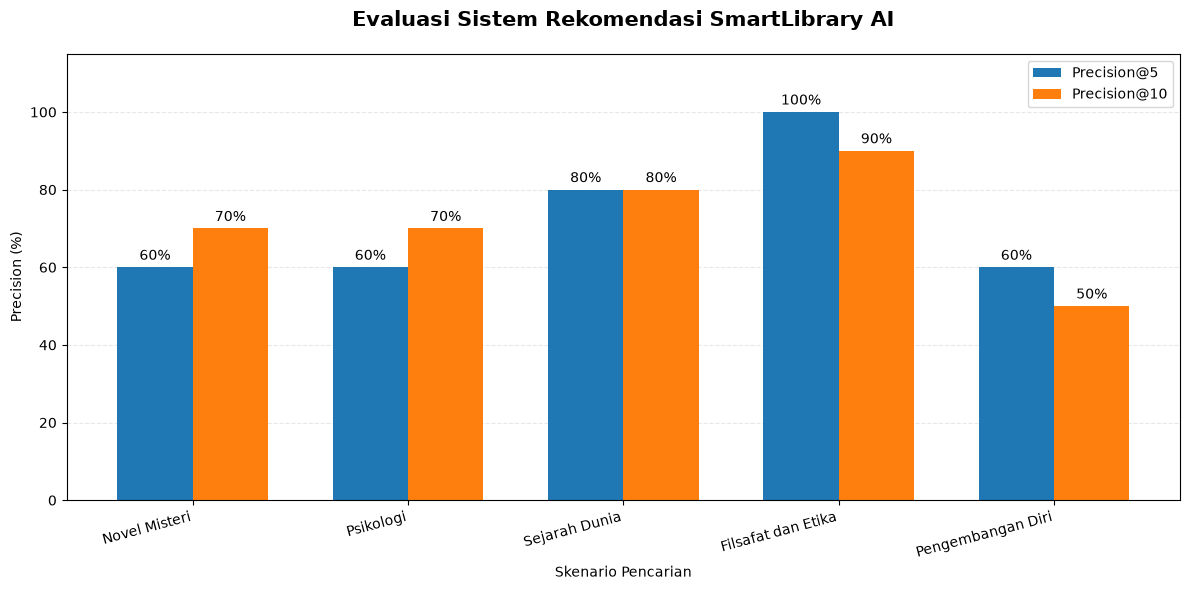

VISUALISASI HASIL EVALUASI
Grafik tersimpan: D:\Project\SmartLibrary_AI\reports\evaluation\precision_comparison.png

[OK] Grafik evaluasi berhasil dibuat.


In [22]:

# =====================================================
# CELL 22 - VISUALISASI HASIL EVALUASI
# =====================================================

import matplotlib.pyplot as plt
import numpy as np

# Menyiapkan data grafik
topics = df_precision["Topik"].tolist()

p5_values = (
    df_precision["Precision@5"].to_numpy() * 100
)

p10_values = (
    df_precision["Precision@10"].to_numpy() * 100
)

x = np.arange(len(topics))
width = 0.35

# Membuat grafik
fig, ax = plt.subplots(figsize=(12, 6))

bars_p5 = ax.bar(
    x - width / 2,
    p5_values,
    width,
    label="Precision@5"
)

bars_p10 = ax.bar(
    x + width / 2,
    p10_values,
    width,
    label="Precision@10"
)

# Menambahkan nilai pada setiap batang
ax.bar_label(
    bars_p5,
    fmt="%.0f%%",
    padding=3
)

ax.bar_label(
    bars_p10,
    fmt="%.0f%%",
    padding=3
)

# Mengatur tampilan grafik
ax.set_title(
    "Evaluasi Sistem Rekomendasi SmartLibrary AI",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Skenario Pencarian")
ax.set_ylabel("Precision (%)")

ax.set_xticks(x)
ax.set_xticklabels(
    topics,
    rotation=15,
    ha="right"
)

ax.set_ylim(0, 115)
ax.legend()

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()

# Menyimpan grafik
GRAPH_PATH = (
    EVAL_DIR / "precision_comparison.png"
)

plt.savefig(
    GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 55)
print("VISUALISASI HASIL EVALUASI")
print("=" * 55)
print("Grafik tersimpan:", GRAPH_PATH)
print("\n[OK] Grafik evaluasi berhasil dibuat.")


In [23]:

# =====================================================
# CELL 23 - ANALISIS KESALAHAN REKOMENDASI
# =====================================================

# Mengambil buku dengan label tidak relevan
df_errors = df_eval[
    df_eval["relevant"] == 0
].copy()

# Mengambil skor similarity dari hasil rekomendasi
df_errors = df_errors.merge(
    df_eval_results[
        [
            "query_id",
            "rank",
            "isbn13",
            "similarity_score"
        ]
    ],
    on=["query_id", "rank", "isbn13"],
    how="left",
    validate="one_to_one"
)

# Mengurutkan berdasarkan skenario dan peringkat
df_errors = df_errors.sort_values(
    ["query_id", "rank"]
)

print("=" * 65)
print("ANALISIS REKOMENDASI TIDAK RELEVAN")
print("=" * 65)

print(
    "Jumlah rekomendasi tidak relevan:",
    len(df_errors)
)

display(
    df_errors[
        [
            "query_id",
            "topic",
            "rank",
            "title",
            "categories",
            "similarity_score",
            "notes"
        ]
    ].style.format({
        "similarity_score": "{:.4f}"
    })
)

# Menghitung kesalahan per skenario
error_summary = (
    df_errors.groupby(
        ["query_id", "topic"]
    )
    .size()
    .reset_index(name="jumlah_tidak_relevan")
)

print("\nRINGKASAN KESALAHAN PER SKENARIO")
display(error_summary)

# Menyimpan hasil analisis
ERROR_PATH = (
    EVAL_DIR / "recommendation_errors.csv"
)

df_errors.to_csv(
    ERROR_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\n[OK] Analisis kesalahan berhasil dibuat.")
print("File tersimpan:", ERROR_PATH)


ANALISIS REKOMENDASI TIDAK RELEVAN
Jumlah rekomendasi tidak relevan: 14


,query_id,topic,rank,title,categories,similarity_score,notes
0,Q01,Novel Misteri,2,Death's Acre,True Crime,0.2133,"Nonfiksi True Crime, bukan novel misteri."
1,Q01,Novel Misteri,3,Philosophical Investigations,Philosophy,0.2066,"Buku filsafat, bukan cerita detektif."
2,Q01,Novel Misteri,10,Category Freaks,Comics & Graphic Novels,0.1314,Fokus pada petualangan paranormal.
3,Q02,Psikologi,1,Myth and Reality,Religion,0.3268,"Fokus pada mitos dan agama, bukan kajian psikologi."
4,Q02,Psikologi,4,The Whore's Child and Other Stories,Human behavior,0.1696,"Kumpulan fiksi, bukan kajian psikologi."
5,Q02,Psikologi,10,CliffsNotes On Joyce's Dubliners,Literary Criticism,0.1154,"Panduan kritik sastra, bukan kajian psikologi."
6,Q03,Sejarah Dunia,5,The Boomer Bible,Humor,0.2407,"Satire dan humor, bukan kajian sejarah."
7,Q03,Sejarah Dunia,9,A Crack in the Edge of the World,History,0.1617,Fokus pada gempa dan geologi lokal.
8,Q04,Filsafat dan Etika,10,The Sunday Philosophy Club,Fiction,0.1812,"Novel misteri, bukan kajian filsafat."
9,Q05,Pengembangan Diri,4,The Curtain,Literary Collections,0.1259,Kajian sejarah dan perkembangan sastra.



RINGKASAN KESALAHAN PER SKENARIO


,query_id,topic,jumlah_tidak_relevan
0,Q01,Novel Misteri,3
1,Q02,Psikologi,3
2,Q03,Sejarah Dunia,2
3,Q04,Filsafat dan Etika,1
4,Q05,Pengembangan Diri,5



[OK] Analisis kesalahan berhasil dibuat.
File tersimpan: D:\Project\SmartLibrary_AI\reports\evaluation\recommendation_errors.csv


In [24]:

# =====================================================
# CELL 24 - SKENARIO PENGUJIAN BILINGUAL
# =====================================================

import importlib
import src.bilingual as bilingual

# Memastikan modul bilingual versi terbaru digunakan
importlib.reload(bilingual)

bilingual_test_queries = pd.DataFrame([
    {
        "query_id": "Q01",
        "topic": "Novel Misteri",
        "query_id_text": (
            "Saya ingin membaca novel misteri tentang "
            "pembunuhan dan penyelidikan detektif"
        ),
        "query_en_text": (
            "Mystery novels about murder "
            "and detective investigations"
        )
    },
    {
        "query_id": "Q02",
        "topic": "Psikologi",
        "query_id_text": (
            "Saya ingin buku tentang psikologi "
            "dan perilaku manusia"
        ),
        "query_en_text": (
            "Books about psychology and human behavior"
        )
    },
    {
        "query_id": "Q03",
        "topic": "Sejarah Dunia",
        "query_id_text": (
            "Saya ingin buku tentang sejarah dunia"
        ),
        "query_en_text": (
            "Books about world history"
        )
    },
    {
        "query_id": "Q04",
        "topic": "Filsafat dan Etika",
        "query_id_text": (
            "Saya ingin buku tentang filsafat dan etika"
        ),
        "query_en_text": (
            "Books about philosophy and ethics"
        )
    },
    {
        "query_id": "Q05",
        "topic": "Pengembangan Diri",
        "query_id_text": (
            "Saya ingin buku tentang kebahagiaan "
            "dan pengembangan diri"
        ),
        "query_en_text": (
            "Books about happiness and personal development"
        )
    }
])

print("=" * 60)
print("SKENARIO PENGUJIAN KONSISTENSI BILINGUAL")
print("=" * 60)

display(bilingual_test_queries)

print("Jumlah pasangan query:", len(bilingual_test_queries))
print("\n[OK] Skenario bilingual berhasil disiapkan.")


SKENARIO PENGUJIAN KONSISTENSI BILINGUAL


,query_id,topic,query_id_text,query_en_text
0,Q01,Novel Misteri,Saya ingin membaca novel misteri tentang pembu...,Mystery novels about murder and detective inve...
1,Q02,Psikologi,Saya ingin buku tentang psikologi dan perilaku...,Books about psychology and human behavior
2,Q03,Sejarah Dunia,Saya ingin buku tentang sejarah dunia,Books about world history
3,Q04,Filsafat dan Etika,Saya ingin buku tentang filsafat dan etika,Books about philosophy and ethics
4,Q05,Pengembangan Diri,Saya ingin buku tentang kebahagiaan dan pengem...,Books about happiness and personal development


Jumlah pasangan query: 5

[OK] Skenario bilingual berhasil disiapkan.


In [25]:

# =====================================================
# CELL 25 - PENGUJIAN KONSISTENSI BILINGUAL
# =====================================================

bilingual_results = []
bilingual_details = []

for _, test in bilingual_test_queries.iterrows():

    query_id = test["query_id"]
    topic = test["topic"]

    try:
        # 1. Memproses input bahasa Indonesia
        info_id = bilingual.prepare_bilingual_query(
            test["query_id_text"],
            language="id"
        )

        # 2. Memproses input bahasa Inggris
        info_en = bilingual.prepare_bilingual_query(
            test["query_en_text"],
            language="en"
        )

        # 3. Menghasilkan rekomendasi
        results_id = recommend_for_evaluation(
            info_id["normalized_query"],
            top_k=10
        )

        results_en = recommend_for_evaluation(
            info_en["normalized_query"],
            top_k=10
        )

        if results_id.empty or results_en.empty:
            raise RuntimeError(
                "Salah satu query tidak menghasilkan rekomendasi."
            )

        # 4. Mengambil ISBN
        isbn_id = results_id["isbn13"].astype(str).tolist()
        isbn_en = results_en["isbn13"].astype(str).tolist()

        # 5. Menghitung jumlah buku yang sama
        common_books = len(
            set(isbn_id).intersection(set(isbn_en))
        )

        # 6. Menghitung Top-10 overlap
        overlap = common_books / 10

        # 7. Membandingkan query dan urutan
        same_query = (
            info_id["normalized_query"]
            == info_en["normalized_query"]
        )

        same_ranking = isbn_id == isbn_en

        # 8. Menyimpan ringkasan
        bilingual_results.append({
            "query_id": query_id,
            "topic": topic,
            "normalized_id": info_id["normalized_query"],
            "normalized_en": info_en["normalized_query"],
            "same_query": same_query,
            "jumlah_id": len(isbn_id),
            "jumlah_en": len(isbn_en),
            "common_books": common_books,
            "overlap_at_10": overlap,
            "same_ranking": same_ranking,
            "status": "Berhasil",
            "error": ""
        })

        # 9. Menyimpan perbandingan judul
        for rank in range(10):
            bilingual_details.append({
                "query_id": query_id,
                "topic": topic,
                "rank": rank + 1,
                "judul_indonesia": (
                    results_id.iloc[rank]["title"]
                    if rank < len(results_id) else ""
                ),
                "judul_inggris": (
                    results_en.iloc[rank]["title"]
                    if rank < len(results_en) else ""
                )
            })

        print(
            f"[OK] {query_id} - {topic}: "
            f"{common_books}/10 buku sama"
        )

    except Exception as error:

        bilingual_results.append({
            "query_id": query_id,
            "topic": topic,
            "normalized_id": "",
            "normalized_en": "",
            "same_query": False,
            "jumlah_id": 0,
            "jumlah_en": 0,
            "common_books": np.nan,
            "overlap_at_10": np.nan,
            "same_ranking": False,
            "status": "Gagal",
            "error": str(error)
        })

        print(
            f"[GAGAL] {query_id}: "
            f"{type(error).__name__} - {error}"
        )

# Membuat DataFrame
df_bilingual_results = pd.DataFrame(
    bilingual_results
)

df_bilingual_details = pd.DataFrame(
    bilingual_details
)

print("\n" + "=" * 60)
print("HASIL PENGUJIAN KONSISTENSI BILINGUAL")
print("=" * 60)

display(
    df_bilingual_results[
        [
            "query_id",
            "topic",
            "same_query",
            "common_books",
            "overlap_at_10",
            "same_ranking",
            "status"
        ]
    ].style.format({
        "overlap_at_10": "{:.2%}"
    }, na_rep="-")
)


[OK] Q01 - Novel Misteri: 6/10 buku sama
[OK] Q02 - Psikologi: 10/10 buku sama
[OK] Q03 - Sejarah Dunia: 10/10 buku sama
[OK] Q04 - Filsafat dan Etika: 7/10 buku sama
[OK] Q05 - Pengembangan Diri: 6/10 buku sama

HASIL PENGUJIAN KONSISTENSI BILINGUAL


,query_id,topic,same_query,common_books,overlap_at_10,same_ranking,status
0,Q01,Novel Misteri,False,6,60.00%,False,Berhasil
1,Q02,Psikologi,True,10,100.00%,True,Berhasil
2,Q03,Sejarah Dunia,True,10,100.00%,True,Berhasil
3,Q04,Filsafat dan Etika,False,7,70.00%,False,Berhasil
4,Q05,Pengembangan Diri,False,6,60.00%,False,Berhasil


In [26]:

# =====================================================
# CELL 26 - RINGKASAN EVALUASI BILINGUAL
# =====================================================

# Mengambil pengujian yang berhasil
successful_tests = df_bilingual_results[
    df_bilingual_results["status"] == "Berhasil"
].copy()

total_tests = len(df_bilingual_results)
success_count = len(successful_tests)
failed_count = total_tests - success_count

print("=" * 60)
print("RINGKASAN EVALUASI BILINGUAL")
print("=" * 60)

print("Total pasangan query :", total_tests)
print("Pengujian berhasil   :", success_count)
print("Pengujian gagal      :", failed_count)

if success_count > 0:

    mean_overlap = successful_tests[
        "overlap_at_10"
    ].mean()

    identical_rank_count = int(
        successful_tests["same_ranking"].sum()
    )

    print(
        f"\nRata-rata Top-10 Overlap: "
        f"{mean_overlap * 100:.2f}%"
    )

    print(
        "Urutan identik         :",
        identical_rank_count,
        "dari",
        success_count
    )

else:
    mean_overlap = np.nan
    print(
        "\n[INFO] Belum ada hasil bilingual "
        "yang dapat diringkas."
    )

# Menyimpan ringkasan
BILINGUAL_PATH = (
    EVAL_DIR / "bilingual_consistency_results.csv"
)

df_bilingual_results.to_csv(
    BILINGUAL_PATH,
    index=False,
    encoding="utf-8-sig"
)

# Menyimpan perbandingan judul
BILINGUAL_DETAIL_PATH = (
    EVAL_DIR / "bilingual_recommendation_details.csv"
)

df_bilingual_details.to_csv(
    BILINGUAL_DETAIL_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nFile ringkasan :", BILINGUAL_PATH)
print("File detail    :", BILINGUAL_DETAIL_PATH)

print("\n[OK] Hasil pengujian bilingual berhasil disimpan.")


RINGKASAN EVALUASI BILINGUAL
Total pasangan query : 5
Pengujian berhasil   : 5
Pengujian gagal      : 0

Rata-rata Top-10 Overlap: 78.00%
Urutan identik         : 2 dari 5

File ringkasan : D:\Project\SmartLibrary_AI\reports\evaluation\bilingual_consistency_results.csv
File detail    : D:\Project\SmartLibrary_AI\reports\evaluation\bilingual_recommendation_details.csv

[OK] Hasil pengujian bilingual berhasil disimpan.


In [27]:

# =====================================================
# CELL 27 - KESIMPULAN AKHIR EVALUASI
# =====================================================

from IPython.display import display, Markdown

# Mengambil ringkasan precision
mean_p5 = df_precision["Precision@5"].mean()
mean_p10 = df_precision["Precision@10"].mean()

# Menentukan topik terbaik dan terendah
best_topic = df_precision.loc[
    df_precision["Precision@10"].idxmax()
]

lowest_topic = df_precision.loc[
    df_precision["Precision@10"].idxmin()
]

# Ringkasan pengujian bilingual
successful_tests = df_bilingual_results[
    df_bilingual_results["status"] == "Berhasil"
]

success_count = len(successful_tests)

if success_count > 0:
    mean_overlap = successful_tests[
        "overlap_at_10"
    ].mean()

    bilingual_summary = (
        f"Dari {len(df_bilingual_results)} pasangan query, "
        f"{success_count} berhasil diuji. "
        f"Rata-rata Top-10 overlap pada pengujian "
        f"yang berhasil sebesar {mean_overlap:.2%}."
    )
else:
    bilingual_summary = (
        "Pengujian bilingual belum memiliki hasil "
        "yang berhasil sehingga konsistensinya "
        "belum dapat disimpulkan."
    )

# Menyusun laporan
report = f"""
# Kesimpulan Evaluasi SmartLibrary AI

## 1. Hasil Evaluasi Relevansi

Sistem rekomendasi buku SmartLibrary AI dikembangkan
menggunakan metode TF-IDF dan Cosine Similarity.

Evaluasi dilakukan terhadap lima skenario pencarian
dengan total 50 rekomendasi buku yang dinilai
berdasarkan kesesuaian judul, kategori, dan sinopsis.

Hasil evaluasi menunjukkan:

- Mean Precision@5: **{mean_p5:.2%}**
- Mean Precision@10: **{mean_p10:.2%}**

Skenario dengan Precision@10 tertinggi adalah
**{best_topic['Topik']}**
({best_topic['Precision@10']:.2%}).

Skenario dengan Precision@10 terendah adalah
**{lowest_topic['Topik']}**
({lowest_topic['Precision@10']:.2%}).

## 2. Evaluasi Konsistensi Bilingual

{bilingual_summary}

Evaluasi menggunakan pasangan query bahasa Indonesia
dan bahasa Inggris dengan pemilihan bahasa manual.

## 3. Analisis Keterbatasan

Sistem masih memiliki beberapa keterbatasan:

1. TF-IDF berfokus pada kemiripan kata sehingga
   belum sepenuhnya memahami makna atau konteks.
2. Buku dengan kata yang cocok belum tentu relevan.
3. Penerjemahan Indonesia-Inggris bergantung pada
   layanan eksternal MyMemory.
4. Evaluasi relevansi didasarkan pada lima skenario
   dan penilaian sinopsis, sehingga belum mewakili
   seluruh kemungkinan permintaan pengguna.
5. Pengujian konsistensi bilingual tidak secara
   langsung mengukur ketepatan relevansi buku.

## 4. Kesimpulan

SmartLibrary AI berhasil mengimplementasikan
rekomendasi buku berbasis NLP menggunakan TF-IDF
dan Cosine Similarity.

Berdasarkan evaluasi awal, sistem memperoleh
rata-rata Precision@5 sebesar {mean_p5:.2%}
dan Precision@10 sebesar {mean_p10:.2%}.

Hasil tersebut menunjukkan bahwa sistem dapat
menghasilkan rekomendasi relevan pada sebagian
besar skenario yang diuji, tetapi kualitas
pemeringkatan masih dapat ditingkatkan.

Pengembangan selanjutnya dapat mempertimbangkan
pembobotan judul dan kategori serta metode
pemahaman semantik yang lebih baik.
"""

# Menampilkan laporan
display(Markdown(report))

# Menyimpan laporan
REPORT_PATH = (
    EVAL_DIR / "evaluation_conclusion.md"
)

REPORT_PATH.write_text(
    report,
    encoding="utf-8"
)

print("\n[OK] Kesimpulan evaluasi berhasil dibuat.")
print("Lokasi:", REPORT_PATH)



# Kesimpulan Evaluasi SmartLibrary AI

## 1. Hasil Evaluasi Relevansi

Sistem rekomendasi buku SmartLibrary AI dikembangkan
menggunakan metode TF-IDF dan Cosine Similarity.

Evaluasi dilakukan terhadap lima skenario pencarian
dengan total 50 rekomendasi buku yang dinilai
berdasarkan kesesuaian judul, kategori, dan sinopsis.

Hasil evaluasi menunjukkan:

- Mean Precision@5: **72.00%**
- Mean Precision@10: **72.00%**

Skenario dengan Precision@10 tertinggi adalah
**Filsafat dan Etika**
(90.00%).

Skenario dengan Precision@10 terendah adalah
**Pengembangan Diri**
(50.00%).

## 2. Evaluasi Konsistensi Bilingual

Dari 5 pasangan query, 5 berhasil diuji. Rata-rata Top-10 overlap pada pengujian yang berhasil sebesar 78.00%.

Evaluasi menggunakan pasangan query bahasa Indonesia
dan bahasa Inggris dengan pemilihan bahasa manual.

## 3. Analisis Keterbatasan

Sistem masih memiliki beberapa keterbatasan:

1. TF-IDF berfokus pada kemiripan kata sehingga
   belum sepenuhnya memahami makna atau konteks.
2. Buku dengan kata yang cocok belum tentu relevan.
3. Penerjemahan Indonesia-Inggris bergantung pada
   layanan eksternal MyMemory.
4. Evaluasi relevansi didasarkan pada lima skenario
   dan penilaian sinopsis, sehingga belum mewakili
   seluruh kemungkinan permintaan pengguna.
5. Pengujian konsistensi bilingual tidak secara
   langsung mengukur ketepatan relevansi buku.

## 4. Kesimpulan

SmartLibrary AI berhasil mengimplementasikan
rekomendasi buku berbasis NLP menggunakan TF-IDF
dan Cosine Similarity.

Berdasarkan evaluasi awal, sistem memperoleh
rata-rata Precision@5 sebesar 72.00%
dan Precision@10 sebesar 72.00%.

Hasil tersebut menunjukkan bahwa sistem dapat
menghasilkan rekomendasi relevan pada sebagian
besar skenario yang diuji, tetapi kualitas
pemeringkatan masih dapat ditingkatkan.

Pengembangan selanjutnya dapat mempertimbangkan
pembobotan judul dan kategori serta metode
pemahaman semantik yang lebih baik.



[OK] Kesimpulan evaluasi berhasil dibuat.
Lokasi: D:\Project\SmartLibrary_AI\reports\evaluation\evaluation_conclusion.md


In [28]:

# =====================================================
# CELL 28 - ANALISIS PERBEDAAN QUERY BILINGUAL
# =====================================================

# Mengambil skenario dengan query berbeda
df_query_diff = df_bilingual_results[
    (df_bilingual_results["status"] == "Berhasil") &
    (df_bilingual_results["same_query"] == False)
].copy()

print("=" * 65)
print("ANALISIS PERBEDAAN NORMALISASI BILINGUAL")
print("=" * 65)

for _, row in df_query_diff.iterrows():

    print("\n" + "-" * 65)
    print("Skenario :", row["query_id"], "-", row["topic"])

    print("\nQuery hasil Indonesia:")
    print(row["normalized_id"])

    print("\nQuery bahasa Inggris:")
    print(row["normalized_en"])

    # Mengambil kata yang berbeda
    words_id = set(row["normalized_id"].split())
    words_en = set(row["normalized_en"].split())

    print("\nKata unik hasil Indonesia:")
    print(sorted(words_id - words_en))

    print("\nKata unik bahasa Inggris:")
    print(sorted(words_en - words_id))

    print(
        "\nTop-10 Overlap:",
        f"{row['overlap_at_10'] * 100:.2f}%"
    )

print("\n[OK] Analisis perbedaan query selesai.")


ANALISIS PERBEDAAN NORMALISASI BILINGUAL

-----------------------------------------------------------------
Skenario : Q01 - Novel Misteri

Query hasil Indonesia:
a mystery novel about murder and detective work

Query bahasa Inggris:
mystery novels about murder and detective investigations

Kata unik hasil Indonesia:
['a', 'novel', 'work']

Kata unik bahasa Inggris:
['investigations', 'novels']

Top-10 Overlap: 60.00%

-----------------------------------------------------------------
Skenario : Q04 - Filsafat dan Etika

Query hasil Indonesia:
i would like a book on philosophy and ethics

Query bahasa Inggris:
philosophy and ethics

Kata unik hasil Indonesia:
['a', 'book', 'i', 'like', 'on', 'would']

Kata unik bahasa Inggris:
[]

Top-10 Overlap: 70.00%

-----------------------------------------------------------------
Skenario : Q05 - Pengembangan Diri

Query hasil Indonesia:
i would like a book on happiness and personal development

Query bahasa Inggris:
happiness and personal develop